# 12. (a)+(b) nonlinear-model MRAC + disturbance-estimator weights

**EXPLORATORY / offline / PROXY.** Reduced taut Newton-Euler model, development PC, **cable at the vehicle centre of mass (`d = 0`)** (Javier, 2026-11-25).

This notebook is a tutorial: every symbol, sign, matrix and cancellation is written out. Running all cells reads cached protocol-08 results and evaluates closed forms. The *live* panel at the end runs one short episode, and only when you press its button.

| Source | Where |
|---|---|
| Notation (residual.tex ↔ MQP ↔ code ↔ Guha) | thesis `.ai/research/derivations/notation-residual-tex.md` |
| Derivation | MQP §6.15 (EQ-MR-23); §6.14.9 (RBF) |
| Code | `experiments/mrac/vanilla_nl_mrac.py`; runner `mrac_lab/extensions_runs.py`; panels `mrac_lab/ext_panels.py` |
| Protocol | protocol 08 (approved 2026-11-25), AM1 (gains fixed before data) |
| Preceding notebook | NB10: vanilla MRAC on the linear outer model (EQ-MR-22) |

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from mrac_lab import provenance, ext_panels, blockdiag
prov = provenance.setup(modules=("experiments.mrac.vanilla_nl_mrac",))
provenance.banner(prov, "Extension series (protocol 08)", notes=("d = 0 (cable at the vehicle CoG)",
                  "Proved: derivative identity only; local convergence conditional (MQP 6.15.5)"))
RES = Path("results")
def latest(stage):
    comp = sorted(RES.glob(f"mrac_ext_{stage}_composite_*"))  # completion parts combined (AM3)
    runs = comp or sorted(RES.glob(f"mrac_ext_{stage}_2*"))
    return runs[-1] if runs else None

Extension series (protocol 08)
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load
Commit: 10f3e8fc92de8f90be001601b6a4fbb5be88d0e7 (branch Claude, clean for experiments/mrac, experiments/notebook_utils/style.py, gym_pymunk_quadrotor)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.vanilla_nl_mrac -> C:\Users\Jcardenasbohorquez\OneDrive - Expleo France\Dokumente\Personal\thesis\gym-pymunk-quadrotor-suspended-load\experiments\mrac\vanilla_nl_mrac.py
Note: d = 0 (cable at the vehicle CoG)
Note: Proved: derivative identity only; local convergence conditional (MQP 6.15.5)


## 1. Notation (residual.tex is primary)

| Symbol | Meaning |
|---|---|
| $\{W\}$, $e_1, e_2$ | world frame, $z$ up, gravity $-g e_2$ |
| $m_q, J_q$ | vehicle mass and pitch inertia |
| $m_b$, $\ell$ | payload mass and rope length (fixed length, inextensible) |
| $M = m_q + m_b$ | total mass |
| $r_q, v_q$, $\theta_q, \omega_q$ | vehicle position, velocity, pitch, rate |
| $u = [f_q, \tau_q]^\top$ | thrust and torque |
| $F = f_q[-\sin\theta_q, \cos\theta_q]^\top$ | the thrust as a world force (the MRAC's virtual input) |
| $\varphi = \mathrm{atan2}(y_q - y_b, z_q - z_b)$ | rope angle (residual.tex) |
| $\hat u = [\sin\varphi, \cos\varphi]^\top$ | rope direction, load to vehicle |
| $\hat q = -\hat u$ | vehicle to load |
| $\hat t = [\cos\varphi, -\sin\varphi]^\top$ | tangent |
| $T^\varphi$ | tension |
| $\mathscr D = [d_{q,y}, d_{q,z}, d_{q,\tau}, d_\varphi]^\top$ | disturbances |
| $x^d$ | **task** state (residual.tex calls it "reference state") |
| $x_r$ | **reference model** (Guha): the nominal vehicle + 4 kg / 2 m payload flown by PID+FF + linear damper |
| $x$ | the real plant |
| $e = x - x_r$ | tracking error |

**Sign map** (code ↔ thesis, valid at $d = 0$): $\varphi_{\rm tex} = -\varphi_{\rm code}$, $\hat q = q_{\rm code}$, $\hat t = t_{\rm code}$.
- Plots show $\varphi_{\rm code}$ and say so.
- Odd functions of $\varphi$ flip sign; $\cos\varphi$, $T^\varphi$, $\hat t$ and $\hat q\hat q^\top$ do not.

## 2. Signal flow (block diagram)

- **Σ symbols** carry their signs.
- **Dashed blocks** are features that are off in this notebook's variant.
- **Real plant:** the only block whose parameters ($m_q, J_q, m_b, \ell$) the controller does not know.
- **Reference model:** a simulation of the nominal system, run alongside the real plant.

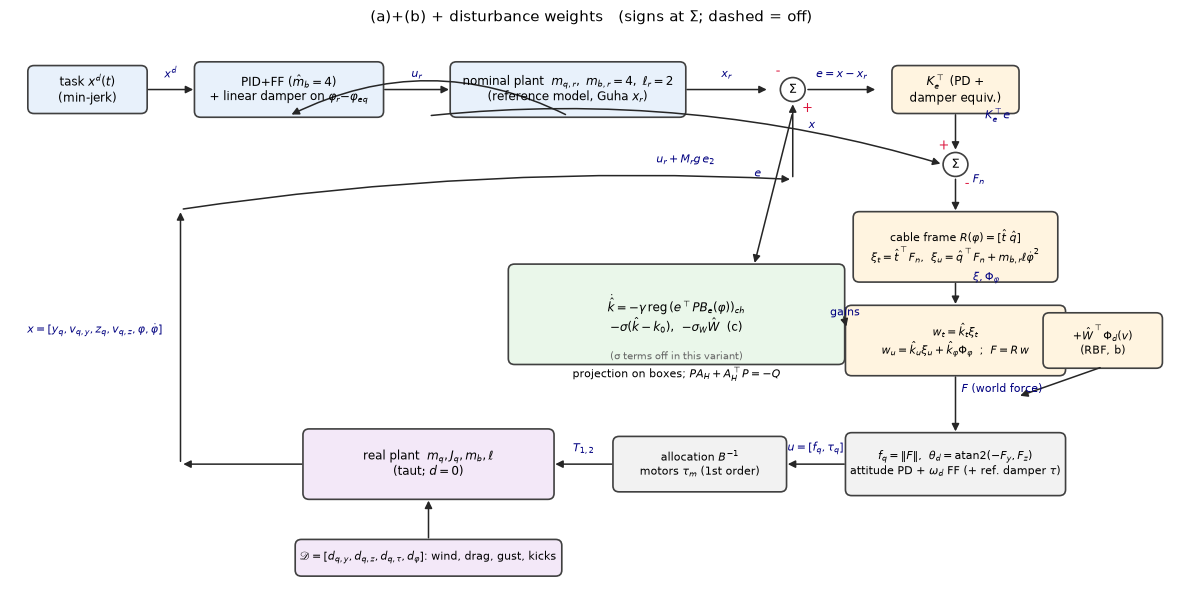

In [2]:
blockdiag.draw_vanilla_extensions("ab"); plt.show()

## 3. The plant, derived step by step ($d = 0$)

**Step 1: Newton for both bodies.** The tension $T^\varphi\ge 0$ pulls the vehicle toward the load (along $\hat q$) and the load toward the vehicle:
$$m_q\ddot r_q = F - m_q g e_2 + T^\varphi\hat q,\qquad m_b\ddot r_b = -T^\varphi\hat q - m_b g e_2,\qquad r_b = r_q + \ell\hat q .$$

**Step 2: the constraint.** Differentiate $r_b = r_q + \ell\hat q(\varphi)$ twice; the rope length is fixed. With $\hat q^\top \partial\hat q/\partial\varphi = 0$, the radial part of the load acceleration is $\hat q^\top\ddot r_b = \hat q^\top\ddot r_q - \ell\dot\varphi^2$ (the centripetal term).

**Step 3: eliminate the tension.** Project the load equation on $\hat q$:
$$T^\varphi = m_b\big(\ell\dot\varphi^2 - g\hat q_z - \hat q^\top\ddot r_q\big) = m_b\big(g\cos\varphi + \hat u^\top\ddot r_q + \ell\dot\varphi^2\big),$$
which is exactly residual.tex eq. (T_hybrid). The tangential projection gives the swing equation, residual.tex eq. (phi_ddot_nl):
$$\ell\ddot\varphi = -g\sin\varphi + \hat t^\top\ddot r_q .$$

**Step 4: substitute back.** Insert $T^\varphi$ into the vehicle equation. With the projectors $P_u = \hat q\hat q^\top$ (radial) and $P_t = \hat t\hat t^\top = I - P_u$ (tangential):
$$\underbrace{(m_q I + m_b P_u)}_{\tilde M(\varphi)}\ddot r_q = F - m_q g e_2 + m_b(\ell\dot\varphi^2 - g\hat q_z)\hat q .$$

$\tilde M = m_q P_t + M P_u$ is the **effective mass**:
- radially, the vehicle drags the whole payload, so the mass is $M$;
- tangentially, the payload swings freely, so the mass is $m_q$.

Its inverse is $\tilde M^{-1} = P_t/m_q + P_u/M$, because the projectors are orthogonal. Gravity collapses to $-g e_2$ in both channels. Result:
$$\boxed{\ddot r_q = \tilde M^{-1}F - g e_2 + \frac{m_b}{M}\ell\dot\varphi^2\,\hat q}$$

This is a Lagrangian elimination in generalized coordinates (not a Hamiltonian form). Below, the closed form is checked against the simulator.

In [3]:
import dataclasses, math
from experiments.mrac.baselines import canonical_offline_params
from experiments.mrac.quad_load_pend import PayloadParams, QuadLoadPend
from experiments.mrac.vanilla_nl_mrac import cable_frame_accel
canon = canonical_offline_params(); rng = np.random.default_rng(0); worst = 0.0
for _ in range(10):
    mq, mb, l = 9.6 * rng.uniform(.8, 1.2), rng.uniform(2, 6), rng.uniform(1.5, 2.5)
    plant = QuadLoadPend(dataclasses.replace(canon.quad, m=mq), PayloadParams(mb, l, 0.0))
    st = canon.with_condition(m_L=mb, cable_length=l).hover_state(theta=rng.uniform(-.3, .3), phi=rng.uniform(-.5, .5), phi_dot=rng.uniform(-1, 1))
    f, _ = plant.wrench(st.quad.c_L, st.quad.c_R)
    F = f * np.array([-math.sin(st.quad.theta), math.cos(st.quad.theta)])
    worst = max(worst, np.abs(cable_frame_accel(F, st.phi, st.phi_dot, m_q=mq, m_b=mb, l=l, g=9.81) - np.array(plant.accelerations(st).p_ddot)).max())
print(f"closed form vs simulator, 10 random taut states: max |difference| = {worst:.1e} m/s^2")

closed form vs simulator, 10 random taut states: max |difference| = 2.2e-15 m/s^2


## 4. Why the cable frame: one scalar effectiveness per channel

Write the world force in the cable frame, $F = R(\varphi)w$ with $R = [\hat t\ \hat q]$. The rotation is known, because $\varphi$ is measured. Then
$$\hat t^\top\ddot r_q = \frac{w_t}{m_q} - g\hat t_z,\qquad \hat q^\top\ddot r_q = \frac{w_u}{M} - g\hat q_z + \frac{m_b}{M}\ell\dot\varphi^2 .$$

Each channel has **one positive scalar effectiveness**, unknown in value but known in sign. This is the structure of Guha's $\lambda$:
$$\lambda_t = m_{q,r}/m_q,\qquad \lambda_u = M_r/M .$$

**Why the cable frame?** A single world-frame scalar $\lambda$ would need $m_b/m_q = m_{b,r}/m_{q,r}$, i.e. proportional masses (Codex 21 N4). The cable frame removes that condition.

**Scope.** The two channels share one state through $B_e(\varphi)$. So this is a **local two-input extension using Guha's scalar-effectiveness and adaptive-law pattern channelwise**, proved in MQP §6.15. Guha's theorem itself is not imported.

## 5. Law, ideal gains and the nominal identity

**Nominal command.** The vanilla error path (NB10) gives the nominal world force: the PD+FF+damper action on $e = x - x_r$,
$$F_n = u_r + M_r g e_2 - K_e^\top e .$$

**Regressors.**
$$\xi_t = \hat t^\top F_n,\qquad \xi_u = \hat q^\top F_n + m_{b,r}\ell\dot\varphi^2,\qquad \Phi_\varphi = -\ell\dot\varphi^2 .$$

**Law.**
$$w_t = \hat k_t\,\xi_t,\qquad w_u = \hat k_u\,\xi_u + \hat k_\varphi\,\Phi_\varphi,\qquad F = R(\varphi)\,w .$$

**Ideal gains.** $k_t^* = m_q/m_{q,r} = 1/\lambda_t$, $k_u^* = M/M_r = 1/\lambda_u$, $k_\varphi^* = m_b$.

**Which terms cancel.** With the ideals, $w_u^*/M + (m_b/M)\ell\dot\varphi^2 = \hat q^\top F_n/M_r + (m_{b,r}/M_r)\ell\dot\varphi^2$. The real payload's centripetal pull is removed and the nominal one restored, so the plant accelerates exactly as the nominal model would under $F_n$.

**Nominal identity.** At the nominal gains $(1, 1, m_{b,r})$, $w = R^\top F_n$, so $F = F_n$. A nominal plant therefore reproduces the reference exactly (checked: $\|e\| < 10^{-10}$).

## 6. Error equation and Lyapunov function, line by line

**1. Error dynamics.** With ideal gains the plant follows the nominal model evaluated at the plant state. Let $\tilde w = (\tilde k_t\xi_t,\ \tilde k_u\xi_u + \tilde k_\varphi\Phi_\varphi)$ and $D = \mathrm{diag}(1/m_q, 1/M)$. Then
$$\dot e = A_H e + N(x, x_r) + B_e(\varphi)\,D\,\tilde w,$$
where:
- $A_H = A_r - B_r K_e^\top$ is Hurwitz (NB10 §3);
- $N$ is the known kinematic remainder of the linearization;
- $B_e(\varphi)$ places a unit channel acceleration in the error rows: velocity along $\hat t$ or $\hat q$, and $\pm 1/\ell$ in the $\dot\varphi$ row for the $t$ channel.

**2. Storage.** As in Guha's $\lambda\tilde k^2/\gamma$:
$$V = e^\top Pe + \frac{\tilde k_t^2}{m_q\gamma_t} + \frac{\tilde k_u^2}{M\gamma_u} + \frac{\tilde k_\varphi^2}{M\gamma_\varphi},\qquad PA_H + A_H^\top P = -Q .$$

**3. Differentiate.**
$$\dot V = -e^\top Qe + 2e^\top PN + 2(e^\top PB_e)_t\frac{\tilde k_t\xi_t}{m_q} + 2(e^\top PB_e)_u\frac{\tilde k_u\xi_u + \tilde k_\varphi\Phi_\varphi}{M} + \frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t} + \dots$$

**4. Choose the updates** so that each cross term cancels its storage term. The unknown $1/m_q$ and $1/M$ factor out, so they are never needed:
$$\dot{\hat k}_t = -\gamma_t\xi_t(e^\top PB_e)_t,\qquad \dot{\hat k}_u = -\gamma_u\xi_u(e^\top PB_e)_u,\qquad \dot{\hat k}_\varphi = -\gamma_\varphi\Phi_\varphi(e^\top PB_e)_u .$$

**5. Result.** $\dot V = -e^\top Qe + 2e^\top PN(x, x_r)$.
- **Proved:** this identity, i.e. the exact cancellation of the parametric uncertainty.
- **Scope:** this establishes cancellation of the displayed matched parametric terms only. No convergence or UUB result for the full nonlinear extension follows without a bound on the total remainder, a valid invariant domain (including the taut-cable region) and a regularity argument.
- **Not proved:** convergence. That needs a bound on $N$ near the trajectory, an invariant region inside the taut domain, and regularity (MQP §6.15.5).
- **Not part of the calculation:** the sampled loop, the projection, the motor lag and the inner attitude loop. They are checked numerically below.


## 6b. Disturbance-estimator weights (b)

**Addition.** Known Gaussian radial basis functions of the vehicle velocity $\Phi_d(v)$ (15 centres) feed the cable-frame weights:
$$w_t \mathrel{+}= \hat W_t^\top\Phi_d,\qquad w_u \mathrel{+}= \hat W_u^\top\Phi_d .$$

**Update** (same cancellation pattern):
$$\dot{\hat W}_j = -\gamma_W\Phi_d\,(e^\top PB_e)_j - \sigma_W\hat W_j,\qquad \sigma_W = 0\ \text{(ab)},\ 0.1\ \text{(abc)}.$$

**What it can represent.**
- **Exactly represented, time-invariant matched disturbance:** its weight cross term can cancel in the displayed continuous-time identity. This does **not** by itself imply $e\to0$, because the nonlinear remainder $N(x,x_r)$ remains in $\dot V$.
- **Drag in a steady wind:** a world-frame force that rotates in the cable frame with $\varphi$ leaves a representation residual. No tracking-convergence or UUB conclusion follows from this identity alone.
- **Time-varying wind** (OU, gust): it is not a fixed state function in this basis. No UUB claim for the full extension is made here.
- **Not compensated:** $d_{q,\tau}$ acts on the inner attitude loop, and $d_\varphi$ is unmatched.


## 7. Before running: the sampled loop is checked locally (per-stage preflight)

The proof is continuous-time; the real tick is sampled at 50 Hz with motor lag. The runner therefore checks every condition before any episode, using a finite-difference Jacobian of one real tick at hover with ideal gains:
- The unexcited gain directions ($\hat k_t$ because $\xi_t = 0$ at hover, $\hat k_\varphi$ because $\dot\varphi = 0$, and the RBF directions orthogonal to $\Phi_d(0)$) are removed structurally. They are checked invariant and with eigenvalue exactly 1.
- The remaining growth rate must be negative.
- $\gamma_u = 0.03$ was fixed by this screen before any protocol data (protocol 08 AM1).

In [4]:
ST = latest("ab")
print("stage folder:", ST)
rec = json.loads((ST / "receipt.json").read_text())
if "composite_of" in rec:  # completion parts combined (protocol 08 AM3)
    print("composite of:", [(p["folder"], p["status"], p.get("n_results")) for p in rec["composite_of"]])
    rec = rec["composite_of"][0]
print("status", rec["status"], "| wall", round(rec.get("wall_s", 0)), "s | thesis", rec["thesis_commit"][:7], "| dirty", rec["dirty_paths"])
display(pd.DataFrame(rec["preflight"]).T.round(4))

stage folder: results\mrac_ext_ab_20261125T140904
status completed | wall 3419 s | thesis 8532158 | dirty []


,rate_per_s,invariance,drift
veh_nominal,-0.1014,0.0,0.0000
veh_m_q-20%,-0.1210,0.0,0.0000
veh_m_q-10%,-0.1104,0.0,0.0000
veh_m_q+10%,-0.0937,0.0,0.0000
veh_m_q+20%,-0.0871,0.0,0.0000
veh_J-30%,-0.1014,0.0,0.0000
veh_J-15%,-0.1014,0.0,0.0000
veh_J+15%,-0.1014,0.0,0.0000
veh_J+30%,-0.1014,0.0,0.0000
veh_a_p-10%,-0.1014,0.0,0.0000


## 8. Results: grid over vehicle and payload mismatch (interactive)

- **Rows:** conditions. These are the 15 vehicle-mismatch cases (mass, inertia, arm, motor asymmetry) at 4 kg / 2 m, plus payload mass and rope length.
- **Columns:** arms. This variant's ONLINE and FROZEN, TUNED' vanilla (`v0_online`), and the PID+FF and softer-damper baselines.
- **Controls:** tick or untick arms, and choose the metric, scenario, disturbance and set.

In [5]:
folders = [latest(s) for s in ['a', 'ab']]
S = ext_panels.load_summaries([f for f in folders if f is not None])
ext_panels.grid_panel(S)

## 9. Episodes: (i) temporal, (ii) gain convergence, (iii) Lyapunov variables (interactive)

Choose a condition, scenario and disturbance, then toggle arms and plot groups.
- The `long` set holds the 600 s transfers, where the gains have time to converge.
- Kicks are at 30 s and 60 s; the red dotted lines mark them.

In [6]:
ext_panels.episode_panel(S)

## 10. Which statement improves which (protocol 08 §6 rule)

"X improves on Y in a disturbance class" when X has the lower task error in at least 75 % of the class's comparable paired cells, **and** the swing gate G3' is *True* for X there. Unknown G3' never passes.
- **Both directions** are scored with each arm's own G3'.
- **A failed episode** makes its cell non-comparable; it never becomes the other arm's win.
- **Scored sets:** only the grid and disturbance sets. The 600 s holds and the `d = 0.3795` runs are readouts.
- **Nature of the test:** descriptive and deterministic (one run per cell, three OU seeds).
- **PE Gramian:** NOT MEASURED in this protocol run, so **no parameter-convergence claim** is made (Codex 27 EXT-05).

In [7]:
from mrac_lab import ext_analysis
an_folders = [f for f in folders if f is not None]
res = ext_analysis.compare(ext_analysis.load(an_folders))
rows = [dict(comparison=p, disturbance=d, comparable=v["comparable"], X_scores=v["x_scores"], X_improves=v["x_improves"],
             Y_scores=v["y_scores"], Y_improves=v["y_improves"], G3_unknown_X=v["g3_unknown_x"],
             failed_X=v["failed_x"], failed_Y=v["failed_y"], median_X=v["median_x"], median_Y=v["median_y"])
        for p, r in res.items() for d, v in r.items()]
display(pd.DataFrame(rows).round(5))
display(ext_analysis.kick_table(ext_analysis.load(an_folders)).round(4))

,comparison,disturbance,comparable,X_scores,X_improves,Y_scores,Y_improves,G3_unknown_X,failed_X,failed_Y,median_X,median_Y
0,a_online vs v0_online,D0 none,42,36,True,6,False,0,0,0,0.00000,0.00000
1,a_online vs v0_online,D1 constant,12,0,False,12,True,0,0,0,0.14238,0.00002
2,a_online vs v0_online,D3 drag,12,0,False,12,True,0,0,0,0.19807,0.00002
3,a_online vs v0_online,D4 gust,12,0,False,12,True,0,0,0,0.18848,0.11899
4,a_online vs v0_online,D2 OU,36,0,False,36,True,0,0,0,0.13281,0.04956
5,a_online vs v0_online,D5 payload kick,12,4,False,8,False,0,0,0,0.05289,0.05284
6,a_online vs v0_online,D6 vehicle kick,12,0,False,12,True,0,0,0,0.06314,0.05431
7,ab_online vs a_online,D0 none,42,5,False,36,True,0,0,0,0.00000,0.00000
8,ab_online vs a_online,D1 constant,12,11,True,0,False,0,0,0,0.00010,0.14238
9,ab_online vs a_online,D3 drag,12,12,True,0,False,0,0,0,0.00017,0.19807


kick0_swing_rms_5s  kick0_task_max_5s  kick0_settle_s  \
dist         arm                                                                
payload_kick a_frozen               0.0585             0.5143            4.37   
             a_online               0.0579             0.3779            4.25   
             ab_frozen              0.0585             0.5143            4.37   
             ab_online              0.0599             0.3553            6.19   
             pidff                  0.0904             0.1491            7.01   
             softer                 0.0753             0.2832            5.84   
             v0_online              0.0627             0.3409            8.54   
vehicle_kick a_frozen               0.0299             0.5231            4.98   
             a_online               0.0299             0.3636            4.90   
             ab_frozen              0.0299             0.5231            4.98   
             ab_online              0.0348             0.3174            6.72   
             pidff                  0.0480             0.2276            6.13   
             softer                 0.0382             0.2469            4.93   
             v0_online              0.0407             0.2774            8.87   

                        kick1_settle_s  
dist         arm                        
payload_kick a_frozen             4.37  
             a_online             4.27  
             ab_frozen            4.37  
             ab_online            5.94  
             pidff                7.01  
             softer               5.84  
             v0_online            8.52  
vehicle_kick a_frozen             4.98  
             a_online             4.90  
             ab_frozen            4.98  
             ab_online            6.46  
             pidff                6.13  
             softer               4.93  
             v0_online            8.82

## 11. Live: tune the gains yourself (one short episode per button press)

In [8]:
ext_panels.live_panel("ab")

## 12. Claim limits

- **Exact:** the cancellation of the parametric uncertainty in the derivative identity, for the continuous, unprojected force-input model at $d = 0$.
- **Not proved:** convergence or UUB for the full nonlinear extension. These require a bound on the total remainder, a valid invariant domain and regularity; exact disturbance representation does not remove $2e^TPN$.
- **Numerical evidence only:** the sampled loop, which is local and finite-horizon, on a single machine (PROXY).
- **Not claimed:**
  - parameter convergence without excitation ($\hat k_\varphi$ needs swing, $\hat k_t$ needs lateral force);
  - results for $d \ne 0$ (the `robust` set is a readout only);
  - Pymunk, hardware or multi-vehicle results.
- **Next:** with Javier's approval, replace the linear damper inside the reference policy by the frozen residual policy.
